# Quantum image ciphers on NEQR reduce to classical permutation-diffusion ciphers

This notebook reproduces every result, table and figure of the study. It runs from top to bottom
without manual steps, writes all intermediate data to `results/` and all figures to `figures/`,
and ends with a section that collects the final numbers.

The study has four parts.

1. **Structure theorem.** A unitary that maps every NEQR image to an NEQR image, with a cipher
   image that determines the plaintext, acts on the pixel array as a position permutation
   followed by an independent value bijection at every position. The representation adds
   nothing to the cipher.
2. **Generic attack.** One chosen-plaintext attack recovers an equivalent key of every
   plaintext-independent cipher of that form, with a query count close to the
   information-theoretic minimum.
3. **Boundaries.** A plaintext-dependent key schedule resists the attack while remaining
   classical, and a measurement outside the computational basis leaves no deterministic
   cipher image.
4. **Metric battery.** A cipher that the attack decrypts completely is statistically equivalent
   to an attack-resistant cipher on entropy, correlation, key sensitivity and PSNR, and passes
   the NIST SP 800-22 tests.

A full run takes about nine minutes on one CPU core and needs about 3.5 GB of memory.

## 1. Setup

All random quantities derive from one global seed through `qic.seeding.rng(tag)`, which mixes
a SHA-256 hash of a text tag with the seed. Secret keys of the experiments come from
`key_for(tag)`. Re-running the notebook in the same environment reproduces every file in
`results/` byte for byte; `results/SHA256SUMS` records the checksums. Machine-dependent
quantities (software versions and wall-clock times) go to `results/run_info.json`, which the
checksums exclude.

In [1]:
import hashlib
import json
import platform
import sys
import time
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
from IPython.display import Markdown, display
from matplotlib.lines import Line2D
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch, Patch

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from qic import attack, images, metrics, neqr, normal_form, plotting, schemes
from qic.seeding import GLOBAL_SEED, rng

FIGURES = ROOT / "figures"
RESULTS = ROOT / "results"
FIGURES.mkdir(exist_ok=True)
RESULTS.mkdir(exist_ok=True)

plotting.apply_style()
OI = plotting.OKABE_ITO
CM = plotting.CM

Q = 8                      # bits per pixel
L = 2 ** Q                 # grey levels
SIDE = 256                 # side of the full-size images
N_FULL = SIDE * SIDE       # pixels of a full-size image

results = {"global_seed": GLOBAL_SEED}
run_info = {"python": sys.version.split()[0], "numpy": np.__version__, "scipy": scipy.__version__,
            "pandas": pd.__version__, "matplotlib": matplotlib.__version__,
            "platform": platform.platform(), "timing_seconds": {}}


def key_for(tag: str) -> int:
    # Secret key of an experiment, derived from the global seed.
    return int(rng(f"key/{tag}").integers(1, 2 ** 31))


def publish(fig, stem, schematic=()):
    # Check the layout, save PNG (600 dpi) and PDF, and display the figure.
    plotting.save(fig, stem, FIGURES, schematic)
    plt.show()


pd.set_option("display.precision", 6)
print(f"global seed {GLOBAL_SEED}; Python {run_info['python']}, NumPy {np.__version__}, "
      f"SciPy {scipy.__version__}, Matplotlib {matplotlib.__version__}")

global seed 20260712; Python 3.13.16, NumPy 2.5.3, SciPy 1.18.1, Matplotlib 3.11.2


## 2. Theoretical background

### 2.1 Images and the NEQR representation

An image with $N=2^{n}$ pixels and $q$ bits per pixel is a vector $I\in\{0,\dots,L-1\}^{N}$ with
$L=2^{q}$ grey levels. A square image of $W\times W$ pixels is flattened row by row, so $N=W^{2}$.
The novel enhanced quantum representation (NEQR) stores the image in a $q$-qubit value register
and an $n$-qubit position register,

$$|\psi_I\rangle=\frac{1}{\sqrt{N}}\sum_{y=0}^{N-1}|I[y]\rangle\otimes|y\rangle .$$

The state is a uniform superposition of $N$ computational basis states, one per position.
Encoding and decoding are classical maps costing $O(Nq)$ operations.

**Lemma 1 (overlap).** For images $I,J$ with Hamming distance
$d_H(I,J)=|\{y: I[y]\neq J[y]\}|$,

$$\langle\psi_I|\psi_J\rangle = 1-\frac{d_H(I,J)}{N}.$$

*Proof.* Basis states with different positions are orthogonal, and at position $y$ the two value
states coincide exactly when $I[y]=J[y]$. $\square$

### 2.2 Ciphers and readout

A keyed quantum image cipher applies a unitary $U_K$ to $|\psi_I\rangle$ and reads a classical
cipher image. Readout is deterministic when the output is again an NEQR state up to phases,

$$U_K|\psi_I\rangle=\frac{1}{\sqrt{N}}\sum_{z=0}^{N-1}e^{i\theta_z(I)}\,|E_K(I)[z]\rangle\otimes|z\rangle ,$$

and the cipher image is then $E_K(I)$. Decryption must recover $I$, so $E_K$ is injective. In the
simulator, readout declares the basis state $|v\rangle|z\rangle$ occupied when its probability
exceeds $1/(2N)$, midway between the only two values, $0$ and $1/N$, that an NEQR state allows,
and it rejects any state in which a position carries zero or several occupied values.

### 2.3 Structure theorem

**Theorem 1.** Let $U_K$ map every NEQR image to an NEQR image up to phases, with $E_K$
injective. Then $E_K$ is an automorphism of the Hamming graph $H(N,L)$, and there are a
permutation $\pi$ of the positions and bijections $\varphi_y$ of the values such that

$$E_K(I)[\pi(y)]=\varphi_y\bigl(I[y]\bigr)\qquad\text{for every image } I \text{ and position } y .$$

*Proof.* (i) $E_K$ is an injective map of the finite set of $L^{N}$ images into itself, hence a
bijection. (ii) Let $I$ and $J$ differ in one pixel. Unitarity and Lemma 1 give
$\langle U_K\psi_I|U_K\psi_J\rangle=1-1/N$. The left side equals
$N^{-1}\sum_{z\in A}e^{i(\theta_z(J)-\theta_z(I))}$, where $A$ is the set of positions at which
$E_K(I)$ and $E_K(J)$ agree, so its real part is at most $1-d/N$ with
$d=d_H(E_K(I),E_K(J))$. Hence $d\le 1$, and $d\ge 1$ by injectivity. (iii) $E_K$ therefore maps
adjacent vertices of $H(N,L)$ to adjacent vertices; a bijection of a finite graph that maps
edges into edges maps the edge set onto itself and is an automorphism. (iv) The automorphism group
of $H(N,L)$ is the wreath product $S_L\wr S_N$ (Brouwer, Cohen and Neumaier, Theorem 9.2.1):
each automorphism permutes the coordinates and permutes the alphabet within each coordinate,
which is the stated form. $\square$

**Corollary 1 (basis-preserving circuits).** A circuit of gates that map computational basis
states to computational basis states acts as a permutation $\sigma(v,y)=(f(v,y),g(v,y))$ of the
value-position pairs. Its cipher image is defined for every image if and only if $g$ does not
depend on $v$, and then $\pi(y)=g(v,y)$ and $\varphi_y=f(\cdot,y)$.

*Proof.* If $g(v,y)=\pi(y)$ the output carries one value per position. If instead
$g(v_1,y_0)\neq g(v_2,y_0)$, the images that agree everywhere except $I[y_0]=v_1$ and
$I'[y_0]=v_2$ send their pixels to multisets of positions that differ in one element, so at least
one of the two repeats a position and has no cipher image. $\square$

**Proposition 1 (value-controlled position gates).** A multiply controlled NOT gate that flips a
position qubit when a value qubit is set is unitary and basis preserving, yet its position map
depends on the value, so by Corollary 1 it leaves the cipher image undefined for some images.
Experiment E2 counts them exhaustively.

**Proposition 2 (dense realisations).** The NEQR states span a subspace $S$ of dimension $N(L-1)+1$; its
orthogonal complement consists of the vectors $\sum_y c_y\sum_v|v\rangle|y\rangle$ with
$\sum_y c_y=0$ and has dimension $N-1$. For a permutation matrix $P_\sigma$ in normal form, an
orthonormal basis $Q$ of $S^{\perp}$ and any unitary $V$ of size $N-1$,

$$U'=P_\sigma\bigl(\Pi_S+QVQ^{\dagger}\bigr)$$

is unitary, dense, and agrees with $P_\sigma$ on every NEQR state. Theorem 1 covers such
non-basis-preserving circuits; Corollary 1 alone would not.

**Corollary 2 (representation independence).** Under the hypotheses of Theorem 1, the quantum
cipher $\mathcal{E}^{\mathrm{Q}}_K$ and the classical cipher $\mathcal{E}^{\mathrm{C}}_K$ that
applies the normal form to the pixel array compute the same function of $(I,K)$. Every adversary
has the same advantage against both in every security game.

**Proposition 3 (bit-plane permutations).** A cipher that permutes the positions of each bit
plane independently can change up to $q$ cipher pixels when one plaintext pixel changes, which
step (ii) of the proof forbids; no unitary realises it on NEQR. On the bit-plane representation
(BRQI), where every bit occupies its own position, Theorem 1 applies with $L=2$ and $qN$
positions.

### 2.4 Generic chosen-plaintext attack

For a plaintext-independent cipher in normal form write $T_z=\varphi_{\pi^{-1}(z)}$ for the
value bijection observed at output position $z$. The pair $(\pi^{-1},\{T_z^{-1}\})$ decrypts
every cipher image produced under the key; it is an *equivalent key*.

**Theorem 2.** An equivalent key is recovered with $m=(L-1)+\lceil\log_L N\rceil$ chosen
plaintexts.

*Construction.* The constant image $I\equiv v$ hides the permutation, so its cipher image gives
$T_z(v)$ at every output position. The queries $v=0,\dots,L-2$ fill the tables; the column
$v=L-1$ holds the one value missing from each row. Tag image $r$ holds at pixel $y$ the digit
$r$ of $y$ in base $L$; applying $T_z^{-1}$ to its cipher image yields the digits of
$\pi^{-1}(z)$. A cipher image $C$ decrypts as $I[\pi^{-1}(z)]=T_z^{-1}(C[z])$. $\square$

**Corollary 3 (specialisations).** If every $\varphi_y$ is an XOR mask, the all-zero image fixes all tables and
$m=1+\lceil\log_L N\rceil$. On the bit-plane representation the same construction with $L=2$
and $qN$ positions costs $m=1+\lceil\log_2(qN)\rceil$ and breaks every cipher that moves and
flips bits, per-plane permutations included.

**Proposition 4 (lower bounds).** A reply carries $Nq$ bits. An attack that recovers the
equivalent key of every cipher in a class $\mathcal{K}$ must distinguish $|\mathcal{K}|$
functions, so $m\ge\lceil\log_2|\mathcal{K}|/(Nq)\rceil$, with $|\mathcal{K}|=N!\,(L!)^{N}$ for
the normal form, $N!\,L^{N}$ for permutation with XOR, and $(qN)!\,2^{qN}$ at bit level.

### 2.5 Scope boundaries

*Plaintext-dependent schedules.* If the keystream depends on a hash of the plaintext, every
query meets a different value layer and Theorem 2 does not apply. Theorem 1 still does: the
cipher remains classical. The receiver needs the hash, which must travel with the cipher image.

*Non-NEQR output.* A gate outside the normal form before measurement, for example a Hadamard or
quantum Fourier transform on the value register, leaves a state that is not an NEQR image.
Measurement then returns random values and no deterministic cipher image exists.

### 2.6 Statistical security metrics

For a cipher image $C$ with grey-level frequencies $p_v$, the entropy is
$H=-\sum_v p_v\log_2 p_v$. For $N$ independent uniform pixels the plug-in estimate has expectation
$q-(L-1)/(2N\ln 2)$ to first order (Miller-Madow bias), which is $7.99719$ bits for $N=65536$,
not $8$. Adjacent-pixel correlation is the Pearson coefficient over all horizontally,
vertically or diagonally adjacent pairs; for an ideal cipher it is $0$ with standard deviation
close to $n_{\mathrm{pairs}}^{-1/2}$. For two cipher images $C_1,C_2$,

$$\mathrm{NPCR}=\frac{100\%}{N}\sum_y[C_1(y)\neq C_2(y)],\qquad
\mathrm{UACI}=\frac{100\%}{N}\sum_y\frac{|C_1(y)-C_2(y)|}{L-1},$$

with ideal values $100\%\,(1-2^{-q})=99.6094\%$ and $100\%\,(L+1)/(3L)=33.4635\%$ for independent
uniform images. *Plaintext sensitivity* compares the cipher images of two plaintexts that differ
in one pixel; *key sensitivity* compares the cipher images of one plaintext under neighbouring
keys. For a plaintext-independent cipher in normal form the plaintext-sensitivity NPCR is exactly
$100\%/N$. $\mathrm{PSNR}=10\log_{10}\bigl((L-1)^2/\mathrm{MSE}\bigr)$ between plain and cipher
image. The NIST SP 800-22 frequency, block frequency, runs, longest run of ones and cumulative
sums tests run on the cipher bit stream, with the second-level proportion and uniformity checks
of the standard over all sequences.

**Proposition 5.** If the keystream is indistinguishable from uniform, a plaintext-independent
cipher and the same cipher with a plaintext-hashed seed give the same distribution of every
statistic computed from one plain image and its cipher image, and of every key-sensitivity
statistic, although Theorem 2 breaks the first and not the second. The battery is therefore
necessary and not sufficient.

Equivalence between two ciphers on a metric is tested with paired two one-sided tests (TOST)
against margins fixed before the analysis: 0.01 bit for entropy, 0.01 for each correlation,
0.10 percentage points for key-sensitivity NPCR and UACI, and 0.50 dB for PSNR.

### 2.7 Computational methodology

Each plaintext-independent cipher is an ordered list of keyed layers executed along three
independent code paths:

* **pixel path**: the layers act on the classical pixel array (the classical cipher
  $\mathcal{E}^{\mathrm{C}}$);
* **state path**: the layers act as unitaries on a dense state vector of dimension $LN$,
  zero amplitudes included, followed by readout (the quantum cipher $\mathcal{E}^{\mathrm{Q}}$);
* **pair path**: the gate tables of the layers are composed into a permutation of
  value-position pairs and factorised into $(\pi,\{\varphi_y\})$.

Agreement between the pixel and state paths tests Corollary 2, and the factorisation of the
pair path provides the ground truth against which recovered equivalent keys are compared.

## 3. Validation of the implementation

Three checks precede the experiments: the NIST tests against the worked examples of
SP 800-22, the reference values of the metric battery against a Monte Carlo estimate with
uniform random images, and Lemma 1 together with the readout threshold on exact NEQR states.

In [2]:
known = pd.DataFrame(metrics.nist_known_answers())
display(known[["test", "expected", "computed", "agrees"]])
assert known["agrees"].all()

gen = rng("validation/uniform")
mc = []
for _ in range(200):
    a, b = gen.integers(0, L, (2, N_FULL))
    mc.append((metrics.entropy(a, Q), metrics.npcr(a, b), metrics.uaci(a, b, Q)))
mc = np.array(mc)
reference = pd.DataFrame({
    "quantity": ["entropy (bit)", "NPCR (%)", "UACI (%)"],
    "closed form": [metrics.expected_entropy_uniform(N_FULL, Q), metrics.npcr_ideal(Q),
                    metrics.uaci_ideal(Q)],
    "Monte Carlo mean": mc.mean(axis=0),
    "Monte Carlo SD": mc.std(axis=0, ddof=1)})
display(reference)

gen = rng("validation/lemma")
pairs = gen.integers(0, 8, (2000, 2, 16))
lemma_error = max(abs(np.vdot(neqr.neqr_state(a, 3), neqr.neqr_state(b, 3)).real
                      - neqr.neqr_overlap(a, b)) for a, b in pairs)
prob = np.abs(neqr.StateVector.from_image(gen.integers(0, L, N_FULL), Q).amp) ** 2
support_values = sorted(set(np.unique(prob).tolist()))

results["validation"] = {
    "nist_examples": int(len(known)), "nist_examples_agreeing": int(known["agrees"].sum()),
    "entropy_expected": metrics.expected_entropy_uniform(N_FULL, Q),
    "npcr_ideal": metrics.npcr_ideal(Q), "uaci_ideal": metrics.uaci_ideal(Q),
    "monte_carlo_images": int(len(mc)),
    "monte_carlo_entropy": float(mc[:, 0].mean()), "monte_carlo_npcr": float(mc[:, 1].mean()),
    "monte_carlo_uaci": float(mc[:, 2].mean()),
    "lemma1_pairs": int(len(pairs)), "lemma1_max_error": float(lemma_error),
    "neqr_probability_values": support_values}
print(f"Lemma 1, {len(pairs)} image pairs: largest deviation {lemma_error:.1e}")
print(f"probabilities on a full-size NEQR state: {support_values} (1/N = {1 / N_FULL})")

,test,expected,computed,agrees
0,frequency,0.527089,0.527089,True
1,frequency,0.109599,0.109599,True
2,block_frequency,0.801252,0.801252,True
3,block_frequency,0.706438,0.706438,True
4,runs,0.147232,0.147232,True
5,runs,0.500798,0.500798,True
6,longest_run,0.180609,0.180609,True
7,cusum_forward,0.411659,0.411659,True
8,cusum_forward,0.219194,0.219194,True
9,cusum_reverse,0.114866,0.114866,True


,quantity,closed form,Monte Carlo mean,Monte Carlo SD
0,entropy (bit),7.997193,7.997176,0.000246
1,NPCR (%),99.609375,99.606903,0.024770
2,UACI (%),33.463542,33.458062,0.094545


Lemma 1, 2000 image pairs: largest deviation 0.0e+00
probabilities on a full-size NEQR state: [0.0, 1.52587890625e-05] (1/N = 1.52587890625e-05)


## 4. Representation independence (Figure 1)

Figure 1 shows the two ways of computing a cipher image that Corollary 2 identifies.

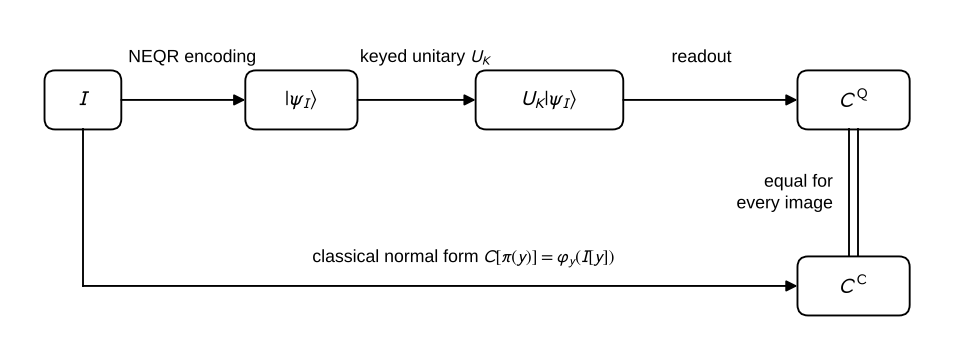

In [3]:
fig = plt.figure(figsize=(plotting.WIDTH_CM * CM, 5.6 * CM))
ax = fig.add_axes((0, 0, 1, 1))
ax.set_xlim(0, plotting.WIDTH_CM)
ax.set_ylim(0, 5.6)
ax.axis("off")


def node(x, y, w, text):
    ax.add_patch(FancyBboxPatch((x - w / 2, y - 0.5), w, 1.0, linewidth=0.9, edgecolor="black",
                                facecolor="white", boxstyle="round,pad=0,rounding_size=0.18"))
    ax.text(x, y, text, ha="center", va="center", fontsize=10)


def arrow(start, end):
    ax.add_patch(FancyArrowPatch(start, end, arrowstyle="-|>", mutation_scale=11,
                                 linewidth=0.9, color="black", shrinkA=0, shrinkB=0))


top, bottom = 4.15, 1.0
xs = {"I": 1.15, "psi": 4.85, "U": 9.05, "CQ": 14.2}
node(xs["I"], top, 1.3, r"$I$")
node(xs["psi"], top, 1.9, r"$|\psi_I\rangle$")
node(xs["U"], top, 2.5, r"$U_K|\psi_I\rangle$")
node(xs["CQ"], top, 1.9, r"$C^{\mathrm{Q}}$")
node(xs["CQ"], bottom, 1.9, r"$C^{\mathrm{C}}$")
arrow((xs["I"] + 0.65, top), (xs["psi"] - 0.95, top))
arrow((xs["psi"] + 0.95, top), (xs["U"] - 1.25, top))
arrow((xs["U"] + 1.25, top), (xs["CQ"] - 0.95, top))
ax.text((xs["I"] + xs["psi"]) / 2, top + 0.64, "NEQR encoding", ha="center", fontsize=8.5)
ax.text((xs["psi"] + xs["U"]) / 2, top + 0.64, r"keyed unitary $U_K$", ha="center", fontsize=8.5)
ax.text((xs["U"] + xs["CQ"]) / 2, top + 0.64, "readout", ha="center", fontsize=8.5)
ax.plot([xs["I"], xs["I"]], [top - 0.5, bottom], color="black", linewidth=0.9)
arrow((xs["I"], bottom), (xs["CQ"] - 0.95, bottom))
ax.text(7.6, bottom + 0.3, r"classical normal form $C[\pi(y)]=\varphi_y(I[y])$",
        ha="center", va="bottom", fontsize=8.5)
for dx in (-0.07, 0.07):
    ax.plot([xs["CQ"] + dx] * 2, [top - 0.5, bottom + 0.5], color="black", linewidth=0.9)
ax.text(xs["CQ"] - 0.35, (top + bottom) / 2, "equal for\nevery image", ha="right", va="center",
        fontsize=8.5, linespacing=1.3)
publish(fig, "fig01_representation_independence", schematic=(ax,))

## 5. Image ensemble (Figure 2)

The ensemble has 12 structured images and 108 power-law fields at $256\times256$ pixels, with
spectral exponents $\beta$ evenly spaced from 1.2 to 3.0. Natural scenes have a power spectrum
close to $1/f^{2}$; Torralba and Oliva report mean exponents between 1.98 and 2.22 across
orientations for more than 3500 natural images. The fitted exponent of every image is
recorded together with its adjacent-pixel correlation and entropy.

family               power-law  structured
spectral_slope mean   2.081040    2.543725
               min    1.210982   -1.143623
               max    2.970451    4.659019
corr_h         mean   0.778524    0.942940
               min    0.398612    0.756863
               max    0.992781    1.000000
corr_v         mean   0.778548    0.924791
               min    0.400468    0.598304
               max    0.992911    1.000000
corr_d         mean   0.717423    0.876862
               min    0.288390    0.445480
               max    0.988539    1.000000
entropy        mean   7.079886    5.830302
               min    6.712091    0.998815
               max    7.506384    8.000000

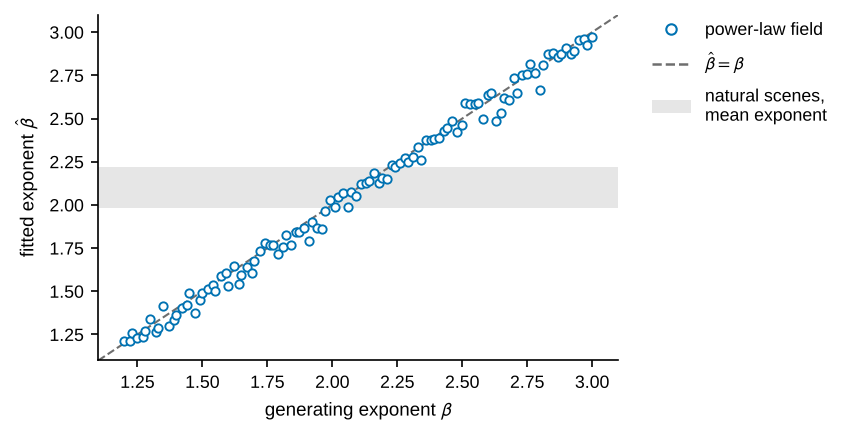

In [4]:
t0 = time.perf_counter()
ensemble = images.make_ensemble(side=SIDE, n_fields=108)
names = [name for name, _ in ensemble]
character = pd.DataFrame([{"image": name,
                           "family": "power-law" if name.startswith("field") else "structured",
                           "nominal_beta": images.nominal_beta(name), **images.characterise(img)}
                          for name, img in ensemble])
character.to_csv(RESULTS / "ensemble_statistics.csv", index=False, float_format="%.10g")
run_info["timing_seconds"]["ensemble"] = time.perf_counter() - t0

fields = character[character.family == "power-law"]
summary = character.groupby("family")[["spectral_slope", "corr_h", "corr_v", "corr_d", "entropy"]]
display(summary.agg(["mean", "min", "max"]).T)
fit_error = fields.spectral_slope - fields.nominal_beta
results["ensemble"] = {
    "images": len(ensemble), "structured": int((character.family == "structured").sum()),
    "fields": int(len(fields)), "beta_min": float(fields.nominal_beta.min()),
    "beta_max": float(fields.nominal_beta.max()),
    "fitted_beta_mean": float(fields.spectral_slope.mean()),
    "fitted_minus_nominal_mean": float(fit_error.mean()),
    "fitted_minus_nominal_max_abs": float(fit_error.abs().max()),
    "fields_in_natural_band": int(((fields.spectral_slope >= 1.98) & (fields.spectral_slope <= 2.22)).sum()),
    "plain_corr_h_mean": float(character.corr_h.mean()),
    "plain_corr_h_fields_mean": float(fields.corr_h.mean()),
    "plain_entropy_mean": float(character.entropy.mean())}

fig, ax = plotting.figure(7.4, legend_cm=5.0)
ax.axhspan(1.98, 2.22, color=plotting.BAND, linewidth=0, zorder=0)
ax.plot([1.1, 3.1], [1.1, 3.1], linestyle="--", color=plotting.GREY, linewidth=1.0, zorder=1)
ax.plot(fields.nominal_beta, fields.spectral_slope, linestyle="none", marker="o", markersize=4,
        markerfacecolor="white", markeredgecolor=OI["blue"], markeredgewidth=0.9, zorder=2)
ax.set_xlim(1.1, 3.1)
ax.set_ylim(1.1, 3.1)
ax.set_xlabel(r"generating exponent $\beta$")
ax.set_ylabel(r"fitted exponent $\hat{\beta}$")
plotting.legend(fig, [plotting.marker_handle({"marker": "o", "color": OI["blue"]}, "power-law field",
                                             filled=False),
                      Line2D([], [], linestyle="--", color=plotting.GREY, label=r"$\hat{\beta}=\beta$"),
                      Patch(facecolor=plotting.BAND, label="natural scenes,\nmean exponent")])
publish(fig, "fig02_ensemble_spectra")

## 6. Experiment E1: representation independence

**Exhaustive small sizes.** For four register sizes every image is encrypted along the pixel path
and along the state path, with and without random phases after the circuit, for schemes A, B, D
and E. A dense non-basis-preserving realisation $U'$ of each circuit, built with a Haar-random
$V$, is applied to every image as well.

**Full size.** Every image of the ensemble is encrypted at $256\times256$ pixels along both
paths, with the four schemes assigned in rotation, and every image is also encrypted with
scheme F along the bit-level state path of the bit-plane representation.

In [5]:
t0 = time.perf_counter()
small_rows = []
for n, q in [(2, 2), (2, 3), (4, 1), (2, 4)]:
    n_pix, levels = 2 ** n, 2 ** q
    every = neqr.all_images(n_pix, q)
    states = neqr.neqr_states(every, q)
    for name in "ABDE":
        cipher = schemes.SCHEMES[name](key_for(f"e1/small/{name}/{n}/{q}"), n_pix, q)
        classical = np.array([cipher.encrypt(img) for img in every])
        phases = rng(f"e1/phases/{name}/{n}/{q}").uniform(0, 2 * np.pi, (levels, n_pix))
        state_mismatch = phase_mismatch = 0
        for img, c in zip(every, classical):
            sv = cipher.encrypt_state(neqr.StateVector.from_image(img, q))
            state_mismatch += not np.array_equal(sv.readout(), c)
            sv.apply_phases(phases)
            phase_mismatch += not np.array_equal(sv.readout(), c)
        pm = cipher.pair_map()
        dense = normal_form.dense_realisation(pm, rng(f"e1/dense/{name}/{n}/{q}"))
        monomial = normal_form.unitary_from_pair_map(pm)
        out = states @ dense.T
        dense_read = neqr.readout_from_amplitudes(out.reshape(-1, levels, n_pix))
        small_rows.append({
            "n": n, "q": q, "scheme": name, "images": len(every),
            "state_mismatches": int(state_mismatch), "phase_mismatches": int(phase_mismatch),
            "dense_mismatches": int(np.any(dense_read != classical, axis=1).sum()),
            "dense_vs_permutation_error": float(np.abs(out - states @ monomial.T).max()),
            "unitarity_error": float(np.abs(dense.conj().T @ dense - np.eye(levels * n_pix)).max()),
            "dense_nonzero_fraction": float(np.mean(np.abs(dense) > 1e-12)),
            "permutation_nonzero_fraction": 1.0 / (levels * n_pix)})
small = pd.DataFrame(small_rows)
run_info["timing_seconds"]["e1_small"] = time.perf_counter() - t0
display(small)

,n,q,scheme,images,state_mismatches,phase_mismatches,dense_mismatches,dense_vs_permutation_error,unitarity_error,dense_nonzero_fraction,permutation_nonzero_fraction
0,2,2,A,256,0,0,0,5.721958e-17,6.661338e-16,1.0,0.062500
1,2,2,B,256,0,0,0,5.721958e-17,4.440892e-16,1.0,0.062500
2,2,2,D,256,0,0,0,1.110231e-16,3.330669e-16,1.0,0.062500
3,2,2,E,256,0,0,0,1.110223e-16,6.661338e-16,1.0,0.062500
4,2,3,A,4096,0,0,0,5.594315e-17,1.110223e-15,1.0,0.031250
5,2,3,B,4096,0,0,0,5.551793e-17,5.551115e-16,1.0,0.031250
6,2,3,D,4096,0,0,0,5.575456e-17,4.440892e-16,1.0,0.031250
7,2,3,E,4096,0,0,0,1.110223e-16,5.551115e-16,1.0,0.031250
8,4,1,A,65536,0,0,0,2.783353e-16,8.881784e-16,1.0,0.031250
9,4,1,B,65536,0,0,0,2.230183e-16,9.992007e-16,1.0,0.031250


In [6]:
t0 = time.perf_counter()
full_rows = []
for i, (name, img) in enumerate(ensemble):
    flat = img.reshape(-1)
    scheme = "ABDE"[i % 4]
    cipher = schemes.SCHEMES[scheme](key_for(f"e1/full/{i}"), N_FULL, Q)
    sv = cipher.encrypt_state(neqr.StateVector.from_image(flat, Q, np.complex64))
    f = schemes.scheme_f(key_for(f"e1/full-f/{i}"), N_FULL, Q)
    bits = neqr.StateVector.from_image(neqr.to_bit_planes(flat, Q), 1, np.complex64)
    f.bit_level_cipher().encrypt_state(bits)
    full_rows.append({"image": name, "scheme": scheme,
                      "match": bool(np.array_equal(sv.readout(), cipher.encrypt(flat))),
                      "match_f_bit_level": bool(np.array_equal(
                          neqr.from_bit_planes(bits.readout(), Q), f.encrypt(flat)))})
full = pd.DataFrame(full_rows)
run_info["timing_seconds"]["e1_full"] = time.perf_counter() - t0

results["e1"] = {
    "small_cases": int(small.images.sum()), "small_rows": small.to_dict("records"),
    "small_state_mismatches": int(small.state_mismatches.sum()),
    "small_phase_mismatches": int(small.phase_mismatches.sum()),
    "small_dense_mismatches": int(small.dense_mismatches.sum()),
    "dense_vs_permutation_max_error": float(small.dense_vs_permutation_error.max()),
    "dense_unitarity_max_error": float(small.unitarity_error.max()),
    "dense_nonzero_fraction_min": float(small.dense_nonzero_fraction.min()),
    "full_images": int(len(full)), "full_state_dimension": L * N_FULL,
    "full_mismatches": int((~full.match).sum()),
    "full_per_scheme": full.groupby("scheme").size().to_dict(),
    "full_f_bit_level_mismatches": int((~full.match_f_bit_level).sum()),
    "full_f_state_dimension": 2 * Q * N_FULL}
print(f"exhaustive cases {results['e1']['small_cases']}: state-path mismatches "
      f"{results['e1']['small_state_mismatches']}, with phases {results['e1']['small_phase_mismatches']}, "
      f"dense realisation {results['e1']['small_dense_mismatches']}")
print(f"full size, {len(full)} images, state dimension {L * N_FULL}: mismatches "
      f"{results['e1']['full_mismatches']}; scheme F on bit planes: "
      f"{results['e1']['full_f_bit_level_mismatches']}")

exhaustive cases 541696: state-path mismatches 0, with phases 0, dense realisation 0
full size, 120 images, state dimension 16777216: mismatches 0; scheme F on bit planes: 0


## 7. Experiment E2: structure theorem (Table 1, Figures 3 and 4)

**Allowed compositions.** Random circuits built from position permutations, XOR masks, modular
additions, bit-plane permutations and per-position substitution boxes are factorised into the
normal form, and the factorisation is checked on every image.

**Excluded gate.** A Toffoli-type gate that flips a position qubit when a value qubit is set is
unitary and basis preserving, but its position map depends on the value. Every image is
enumerated to count those without a cipher image.

**Bit-plane permutations.** One pixel of a full-size image is changed at random 2000 times and
the number of changed cipher pixels is recorded for every scheme.

In [7]:
gen = rng("e2/compositions")
composition_rows = []
for n, q in [(2, 2), (2, 3), (3, 2)]:
    n_pix, levels = 2 ** n, 2 ** q
    gates = [normal_form.position_permutation(gen.permutation(n_pix), q),
             normal_form.xor_layer(gen.integers(0, levels, n_pix), q),
             normal_form.addition_layer(gen.integers(0, levels, n_pix), q),
             normal_form.bitplane_layer(gen.permutation(q), n_pix, q),
             normal_form.substitution_layer(np.array([gen.permutation(levels) for _ in range(n_pix)]), q),
             normal_form.position_permutation(gen.permutation(n_pix), q)]
    pm = normal_form.identity(n_pix, q)
    for gate in gates:
        pm = normal_form.compose(pm, gate)
    ok, info = normal_form.check_well_defined(pm)
    pi, phi = normal_form.factorize(pm)
    every = neqr.all_images(n_pix, q)
    exact = all(np.array_equal(normal_form.apply_normal_form(img, pi, phi),
                               normal_form.apply_pair_map(img, pm))
                and np.array_equal(normal_form.invert_normal_form(
                    normal_form.apply_normal_form(img, pi, phi), pi, phi), img) for img in every)
    composition_rows.append({"n": n, "q": q, "gates": len(gates),
                             "basis_permutation": normal_form.is_basis_permutation(pm),
                             "normal_form": ok, "images_checked": len(every), "exact": exact})
compositions = pd.DataFrame(composition_rows)
display(compositions)

excluded_rows = []
for n, q in [(2, 2), (2, 3), (3, 2)]:
    gate = normal_form.value_controlled_position_flip(0, 0, 2 ** n, q)
    ok, info = normal_form.check_well_defined(gate)
    undefined, total = normal_form.count_undefined_images(gate)
    excluded_rows.append({"n": n, "q": q, "basis_permutation": normal_form.is_basis_permutation(gate),
                          "normal_form": ok, "undefined": undefined, "total": total,
                          "percent": 100 * undefined / total,
                          "witness_a": info["image_a"].tolist(), "witness_b": info["image_b"].tolist()})
excluded = pd.DataFrame(excluded_rows)
display(excluded.drop(columns=["witness_a", "witness_b"]))

,n,q,gates,basis_permutation,normal_form,images_checked,exact
0,2,2,6,True,True,256,True
1,2,3,6,True,True,4096,True
2,3,2,6,True,True,65536,True


,n,q,basis_permutation,normal_form,undefined,total,percent
0,2,2,True,False,192,256,75.00
1,2,3,True,False,3072,4096,75.00
2,3,2,True,False,61440,65536,93.75


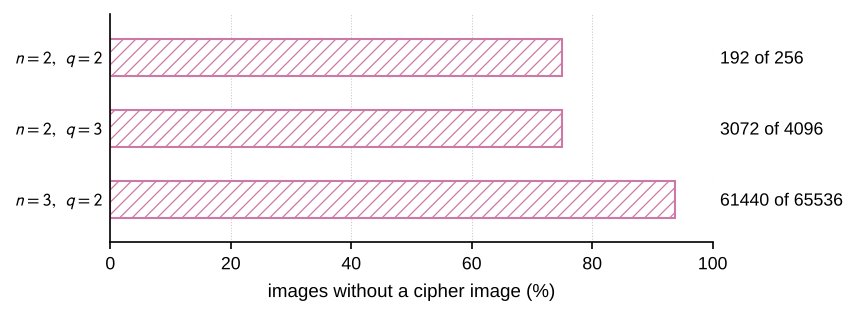

In [8]:
fig, ax = plotting.figure(5.4, left_cm=2.4, right_cm=3.4)
ypos = np.arange(len(excluded))[::-1]
ax.barh(ypos, excluded.percent, height=0.52, color="white", edgecolor=OI["purple"],
        hatch="////", linewidth=1.0, zorder=2)
ax.set_yticks(ypos)
ax.set_yticklabels([rf"$n={n},\ q={q}$" for n, q in zip(excluded.n, excluded.q)])
ax.tick_params(axis="y", length=0)
ax.set_xlim(0, 100)
ax.set_ylim(-0.6, len(excluded) - 0.4)
ax.set_xlabel("images without a cipher image (%)")
ax.grid(axis="x", linestyle=":", linewidth=0.5, color="#C8C8C8", zorder=0)
counts = ax.twinx()
counts.set_ylim(ax.get_ylim())
counts.set_yticks(ypos)
counts.set_yticklabels([f"{u} of {t}" for u, t in zip(excluded.undefined, excluded.total)])
counts.tick_params(axis="y", length=0)
for spine in counts.spines.values():
    spine.set_visible(False)
publish(fig, "fig03_excluded_gate")

,A,B,D,E,F
changed pixels,,,,,
1,100.0,100.0,100.0,100.0,4.15
2,0.0,0.0,0.0,0.0,10.50
3,0.0,0.0,0.0,0.0,23.80
4,0.0,0.0,0.0,0.0,27.35
5,0.0,0.0,0.0,0.0,20.30
6,0.0,0.0,0.0,0.0,10.65
7,0.0,0.0,0.0,0.0,2.95
8,0.0,0.0,0.0,0.0,0.30


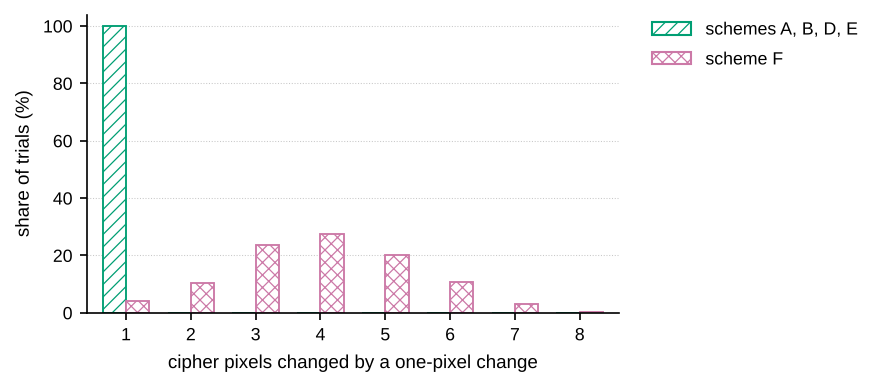

In [9]:
spread_image = ensemble[12][1].reshape(-1)
spread = {}
for name in "ABDEF":
    cipher = schemes.SCHEMES[name](key_for(f"e2/spread/{name}"), N_FULL, Q)
    spread[name] = normal_form.single_pixel_spread(cipher.encrypt, spread_image,
                                                   rng(f"e2/spread/{name}"), 2000, Q)
distances = np.arange(1, Q + 1)
share = {name: np.array([np.mean(d == k) for k in distances]) for name, d in spread.items()}
display(pd.DataFrame({name: 100 * s for name, s in share.items()}, index=distances).rename_axis("changed pixels"))

results["e2"] = {
    "compositions": composition_rows,
    "excluded_gate": [{k: v for k, v in r.items() if not k.startswith("witness")} for r in excluded_rows],
    "excluded_witness_n2_q2": {"image_a": excluded_rows[0]["witness_a"], "image_b": excluded_rows[0]["witness_b"]},
    "spread_trials": 2000,
    "spread_max_normal_form": int(max(spread[s].max() for s in "ABDE")),
    "spread_min_normal_form": int(min(spread[s].min() for s in "ABDE")),
    "spread_f_share_above_one": float(np.mean(spread["F"] > 1)),
    "spread_f_mean": float(spread["F"].mean()), "spread_f_max": int(spread["F"].max()),
    "spread_f_distribution": {int(k): float(v) for k, v in zip(distances, share["F"])}}

pooled = np.mean([share[s] for s in "ABDE"], axis=0)
fig, ax = plotting.figure(6.6, legend_cm=4.8)
width = 0.36
ax.bar(distances - width / 2, 100 * pooled, width=width, color="white", edgecolor=OI["green"],
       hatch="////", linewidth=0.9, zorder=2)
ax.bar(distances + width / 2, 100 * share["F"], width=width, color="white", edgecolor=OI["purple"],
       hatch="xxxx", linewidth=0.9, zorder=2)
ax.set_xticks(distances)
ax.set_xlim(0.4, Q + 0.6)
ax.set_ylim(0, 104)
ax.set_xlabel("cipher pixels changed by a one-pixel change")
ax.set_ylabel("share of trials (%)")
ax.grid(axis="y", linestyle=":", linewidth=0.5, color="#C8C8C8", zorder=0)
plotting.legend(fig, [Patch(facecolor="white", edgecolor=OI["green"], hatch="////", label="schemes A, B, D, E"),
                      Patch(facecolor="white", edgecolor=OI["purple"], hatch="xxxx", label="scheme F")])
publish(fig, "fig04_single_pixel_spread")

## 8. Experiment E3: generic attack (Figures 5 to 8)

**Worked example.** Scheme A encrypts a $128\times128$ test image; the generic attack recovers an
equivalent key, and the XOR fast path is run with a growing query budget.

**Coverage.** For each scheme, five keys at $256\times256$ pixels are attacked with the generic
attack, the XOR fast path and the bit-level attack. A recovered equivalent key is compared with
the ground truth from the pair path, which makes exact recovery a deterministic statement rather
than an estimate; three held-out random images per key confirm decryption.

**Scaling.** Query counts are measured for $N$ from $2^{4}$ to $2^{20}$ and compared with
Theorem 2, Corollary 3 and Proposition 4.

**Boundaries.** Scheme C seeds its keystream from a plaintext hash. A Hadamard gate on the most
significant value qubit after scheme A leaves a state that is not an NEQR image.

,queries,recovered
0,1,0.000061
1,2,0.000122
2,3,1.000000


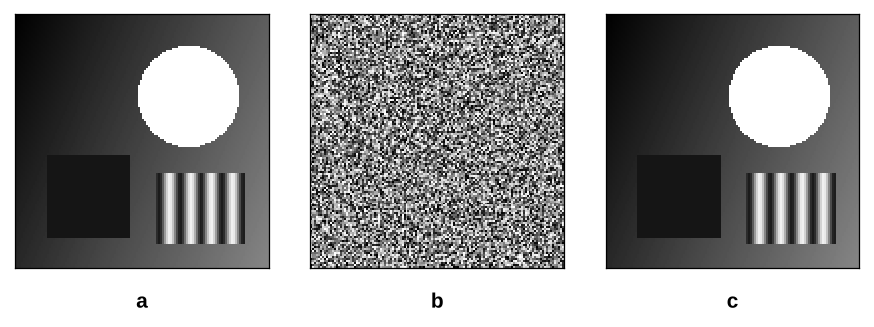

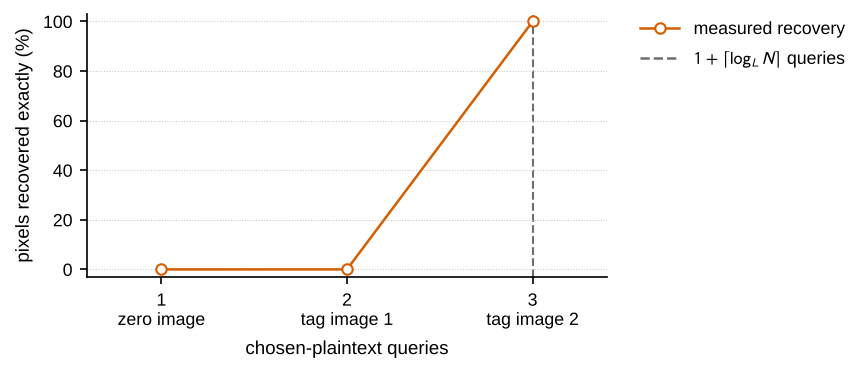

In [10]:
demo = images.demo_image(128).reshape(-1)
n_demo = demo.size
demo_cipher = schemes.scheme_a(key_for("e3/demo"), n_demo, Q)
demo_enc = demo_cipher.encrypt(demo)
demo_key = attack.generic_attack(demo_cipher.oracle(), n_demo, Q)
demo_rec = demo_key.decrypt(demo_enc)
budget_rows = []
for budget in range(1, attack.xor_cost(n_demo, Q) + 1):
    key = attack.xor_attack(demo_cipher.oracle(), n_demo, Q, budget=budget)
    budget_rows.append({"queries": key.queries,
                        "recovered": attack.pixel_accuracy(key.decrypt(demo_enc), demo)})
budget_table = pd.DataFrame(budget_rows)
display(budget_table)
results["e3_demo"] = {"pixels": n_demo, "generic_queries": demo_key.queries,
                      "generic_recovered": attack.pixel_accuracy(demo_rec, demo),
                      "xor_budget": budget_rows}

fig = plt.figure(figsize=(plotting.WIDTH_CM * CM, 6.1 * CM))
panel, left, gap, base = 4.3, 0.85, 0.7, 1.0
for k, (img, letter) in enumerate([(demo, "a"), (demo_enc, "b"), (demo_rec, "c")]):
    x0 = left + k * (panel + gap)
    axk = fig.add_axes((x0 / plotting.WIDTH_CM, base / 6.1, panel / plotting.WIDTH_CM, panel / 6.1))
    axk.imshow(img.reshape(128, 128), cmap="gray", vmin=0, vmax=L - 1)
    axk.set_xticks([])
    axk.set_yticks([])
    for spine in axk.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(0.6)
    fig.text((x0 + panel / 2) / plotting.WIDTH_CM, 0.42 / 6.1, letter, ha="center", va="center",
             fontsize=10, fontweight="bold")
publish(fig, "fig05_attack_example")

fig, ax = plotting.figure(6.6, legend_cm=5.0, bottom_cm=1.85)
ax.plot(budget_table.queries, 100 * budget_table.recovered, color=OI["vermillion"], marker="o",
        markerfacecolor="white", markeredgewidth=1.0, zorder=3)
ax.axvline(attack.xor_cost(n_demo, Q), linestyle="--", color=plotting.GREY, linewidth=1.0, zorder=1)
ax.set_xticks(budget_table.queries)
ax.set_xticklabels(["1\nzero image", "2\ntag image 1", "3\ntag image 2"])
ax.set_xlim(0.6, 3.4)
ax.set_ylim(-3, 103)
ax.set_xlabel("chosen-plaintext queries")
ax.set_ylabel("pixels recovered exactly (%)")
ax.grid(axis="y", linestyle=":", linewidth=0.5, color="#C8C8C8", zorder=0)
plotting.legend(fig, [Line2D([], [], color=OI["vermillion"], marker="o", markerfacecolor="white",
                             label="measured recovery"),
                      Line2D([], [], linestyle="--", color=plotting.GREY,
                             label=r"$1+\lceil\log_{L}N\rceil$ queries")])
publish(fig, "fig06_recovery_vs_queries")

queries             recovered                     exact_keys          \
attack bit-level generic xor bit-level   generic       xor  bit-level generic   
scheme                                                                          
A             20     257   3  1.000000  1.000000  1.000000          5       5   
B             20     257   3  1.000000  1.000000  0.004004          5       5   
C             20     257   3  0.003926  0.003927  0.003882          0       0   
D             20     257   3  0.034995  1.000000  0.015205          0       5   
E             20     257   3  0.007344  1.000000  0.003876          0       5   
F             20     257   3  1.000000  0.003992  0.003992          5       0   

            
attack xor  
scheme      
A        5  
B        0  
C        0  
D        0  
E        0  
F        0

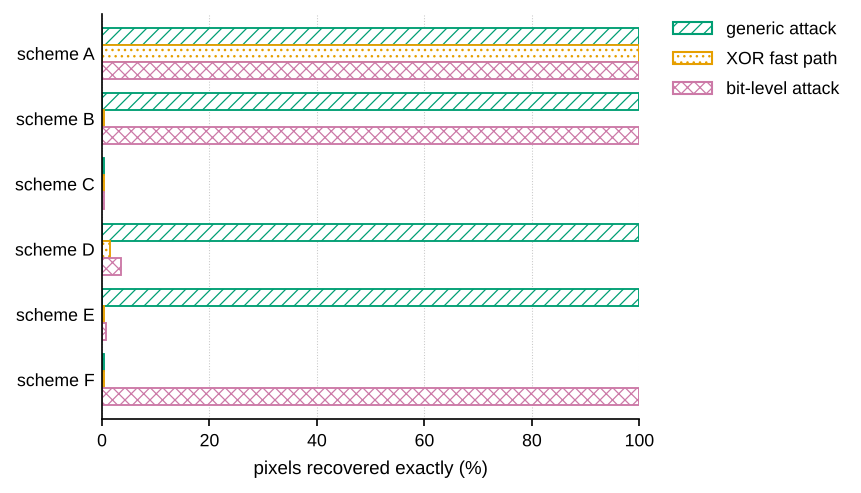

In [11]:
t0 = time.perf_counter()
coverage_rows = []
for name in "ABCDEF":
    for k in range(5):
        cipher = schemes.SCHEMES[name](key_for(f"e3/coverage/{name}/{k}"), N_FULL, Q)
        secrets = rng(f"e3/coverage/secret/{name}/{k}").integers(0, L, (3, N_FULL))
        ciphertexts = [cipher.encrypt(s) for s in secrets]
        truth = {}
        if name in "ABDE":
            pi, phi = cipher.normal_form()
            truth["generic"] = truth["xor"] = (pi, phi)
            bit_form = normal_form.bit_level_form(pi, phi, Q)
            if bit_form is not None:
                truth["bit-level"] = bit_form
        elif name == "F":
            truth["bit-level"] = cipher.bit_level_cipher().normal_form()
        attacks = {"generic": lambda: attack.generic_attack(cipher.oracle(), N_FULL, Q),
                   "xor": lambda: attack.xor_attack(cipher.oracle(), N_FULL, Q),
                   "bit-level": lambda: attack.bit_level_attack(cipher.oracle(), N_FULL, Q)}
        for label, run in attacks.items():
            start = time.perf_counter()
            key = run()
            elapsed = time.perf_counter() - start
            recovered = [attack.pixel_accuracy(key.decrypt(c), s) for c, s in zip(ciphertexts, secrets)]
            inner = key.key if label == "bit-level" else key
            key_exact = attack.key_matches(inner, *truth[label]) if label in truth else None
            coverage_rows.append({"scheme": name, "key_index": k, "attack": label,
                                  "queries": key.queries, "recovered_mean": float(np.mean(recovered)),
                                  "recovered_min": float(np.min(recovered)),
                                  "all_exact": bool(min(recovered) == 1.0), "key_matches_truth": key_exact,
                                  "seconds": elapsed})
coverage = pd.DataFrame(coverage_rows)
coverage.drop(columns="seconds").to_csv(RESULTS / "attack_coverage.csv", index=False, float_format="%.10g")
run_info["timing_seconds"]["e3_coverage"] = time.perf_counter() - t0
run_info["timing_seconds"]["attack_full_size"] = {
    f"{s}/{a}": float(v) for (s, a), v in coverage.groupby(["scheme", "attack"]).seconds.mean().items()}

table = coverage.groupby(["scheme", "attack"]).agg(queries=("queries", "first"),
                                                   recovered=("recovered_mean", "mean"),
                                                   exact_keys=("all_exact", "sum"))
display(table.unstack("attack"))
results["e3_coverage"] = {
    f"{s}/{a}": {"queries": int(g.queries.iloc[0]), "recovered_mean": float(g.recovered_mean.mean()),
                 "exact_keys": int(g.all_exact.sum()), "keys": int(len(g)),
                 "key_matches_truth": None if g.key_matches_truth.isna().all()
                 else int(g.key_matches_truth.fillna(False).astype(bool).sum())}
    for (s, a), g in coverage.groupby(["scheme", "attack"])}

order = list("ABCDEF")
attack_styles = [("generic", "generic attack", OI["green"], "////"),
                 ("xor", "XOR fast path", OI["orange"], "...."),
                 ("bit-level", "bit-level attack", OI["purple"], "xxxx")]
fig, ax = plotting.figure(8.4, legend_cm=4.6, left_cm=2.0)
base = np.arange(len(order))[::-1] * 1.0
height = 0.26
for j, (label, text, colour, hatch) in enumerate(attack_styles):
    values = [100 * table.loc[(s, label), "recovered"] for s in order]
    ax.barh(base + (1 - j) * height, values, height=height, color="white", edgecolor=colour,
            hatch=hatch, linewidth=0.9, zorder=2)
ax.set_yticks(base)
ax.set_yticklabels([f"scheme {s}" for s in order])
ax.tick_params(axis="y", length=0)
ax.set_ylim(-0.6, len(order) - 0.4)
ax.set_xlim(0, 100)
ax.set_xlabel("pixels recovered exactly (%)")
ax.grid(axis="x", linestyle=":", linewidth=0.5, color="#C8C8C8", zorder=0)
plotting.legend(fig, [Patch(facecolor="white", edgecolor=c, hatch=h, label=t) for _, t, c, h in attack_styles])
publish(fig, "fig07_attack_coverage")

,side,pixels,generic_theory,generic_bound,xor_theory,xor_bound,bit_theory,bit_bound,xor_measured,xor_exact,bit_measured,bit_exact,generic_measured,generic_exact
0,4,16,256,211,2,2,8,7,2,True,8,True,256.0,True
1,8,64,256,212,2,2,10,9,2,True,10,True,256.0,True
2,16,256,256,212,2,2,12,11,2,True,12,True,256.0,True
3,32,1024,257,212,3,3,14,13,3,True,14,True,257.0,True
4,64,4096,257,212,3,3,16,15,3,True,16,True,257.0,True
5,128,16384,257,213,3,3,18,17,3,True,18,True,257.0,True
6,256,65536,257,213,3,3,20,19,3,True,20,True,257.0,True
7,512,262144,258,213,4,4,22,21,4,True,22,True,NaN,NaN
8,1024,1048576,258,213,4,4,24,23,4,True,24,True,NaN,NaN


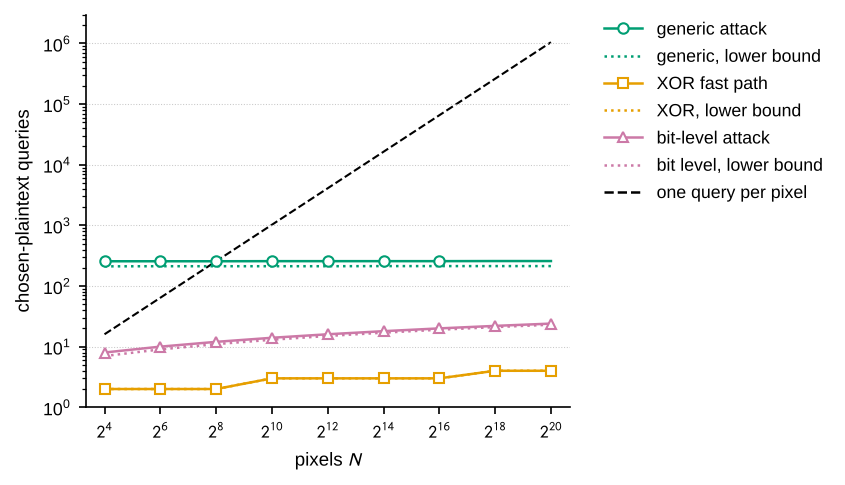

In [12]:
t0 = time.perf_counter()
scaling_rows = []
for side in [4, 8, 16, 32, 64, 128, 256, 512, 1024]:
    n_pix = side * side
    a = schemes.scheme_a(key_for(f"e3/scaling/A/{side}"), n_pix, Q)
    f = schemes.scheme_f(key_for(f"e3/scaling/F/{side}"), n_pix, Q)
    secret = rng(f"e3/scaling/secret/{side}").integers(0, L, n_pix)
    row = {"side": side, "pixels": n_pix,
           "generic_theory": attack.generic_cost(n_pix, Q), "generic_bound": attack.generic_lower_bound(n_pix, Q),
           "xor_theory": attack.xor_cost(n_pix, Q), "xor_bound": attack.xor_lower_bound(n_pix, Q),
           "bit_theory": attack.bit_level_cost(n_pix, Q), "bit_bound": attack.bit_level_lower_bound(n_pix, Q)}
    key = attack.xor_attack(a.oracle(), n_pix, Q)
    row["xor_measured"] = key.queries
    row["xor_exact"] = bool(np.array_equal(key.decrypt(a.encrypt(secret)), secret))
    key = attack.bit_level_attack(f.oracle(), n_pix, Q)
    row["bit_measured"] = key.queries
    row["bit_exact"] = bool(np.array_equal(key.decrypt(f.encrypt(secret)), secret))
    if n_pix <= N_FULL:
        e = schemes.scheme_e(key_for(f"e3/scaling/E/{side}"), n_pix, Q)
        key = attack.generic_attack(e.oracle(), n_pix, Q)
        row["generic_measured"] = key.queries
        row["generic_exact"] = bool(np.array_equal(key.decrypt(e.encrypt(secret)), secret))
    scaling_rows.append(row)
scaling = pd.DataFrame(scaling_rows)
scaling.to_csv(RESULTS / "query_scaling.csv", index=False)
run_info["timing_seconds"]["e3_scaling"] = time.perf_counter() - t0
display(scaling)
results["e3_scaling"] = scaling.astype(object).where(scaling.notna(), None).to_dict("records")

fig, ax = plotting.figure(8.2, legend_cm=5.6)
pix = scaling.pixels.to_numpy()
series = [("generic", OI["green"], "o", "generic attack", "generic, lower bound"),
          ("xor", OI["orange"], "s", "XOR fast path", "XOR, lower bound"),
          ("bit", OI["purple"], "^", "bit-level attack", "bit level, lower bound")]
handles = []
for key, colour, marker, text, bound_text in series:
    ax.plot(pix, scaling[f"{key}_theory"], color=colour, linewidth=1.2, zorder=2)
    measured = scaling[f"{key}_measured"].to_numpy(dtype=float)
    ax.plot(pix, measured, linestyle="none", marker=marker, color=colour, markerfacecolor="white",
            markeredgewidth=1.0, zorder=3)
    ax.plot(pix, scaling[f"{key}_bound"], color=colour, linestyle=":", linewidth=1.2, zorder=2)
    handles.append(Line2D([], [], color=colour, marker=marker, markerfacecolor="white", label=text))
    handles.append(Line2D([], [], color=colour, linestyle=":", label=bound_text))
ax.plot(pix, pix, color="black", linestyle="--", linewidth=1.0, zorder=1)
handles.append(Line2D([], [], color="black", linestyle="--", label="one query per pixel"))
ax.set_xscale("log", base=2)
ax.set_yscale("log")
ax.set_xticks(pix)
ax.set_xticklabels([f"$2^{{{int(np.log2(p))}}}$" for p in pix])
ax.xaxis.set_minor_locator(matplotlib.ticker.NullLocator())
ax.set_xlim(pix[0] / 1.6, pix[-1] * 1.6)
ax.set_ylim(1, 3e6)
ax.set_xlabel(r"pixels $N$")
ax.set_ylabel("chosen-plaintext queries")
ax.grid(axis="y", which="major", linestyle=":", linewidth=0.5, color="#C8C8C8", zorder=0)
plotting.legend(fig, handles, labelspacing=0.6)
publish(fig, "fig08_query_cost")

In [13]:
boundary_image = ensemble[20][1].reshape(-1)
a = schemes.scheme_a(key_for("e3/boundary/hadamard"), N_FULL, Q)
sv = a.encrypt_state(neqr.StateVector.from_image(boundary_image, Q, np.complex64))
sv.hadamard_value_qubit(Q - 1)
try:
    sv.readout()
    readout_message = "readout succeeded"
except ValueError as error:
    readout_message = str(error)
gen = rng("e3/boundary/measurement")
first, second = sv.sample_image(gen), sv.sample_image(gen)
c_rows = coverage[coverage.scheme == "C"]
results["e3_boundaries"] = {
    "plaintext_dependent_recovered_max": float(c_rows.recovered_mean.max()),
    "plaintext_dependent_recovered_mean": float(c_rows.recovered_mean.mean()),
    "chance_level": 1 / L,
    "hadamard_readout": readout_message,
    "hadamard_two_readouts_differ": float(np.mean(first != second)),
    "hadamard_decrypted_correct": float(np.mean(a.decrypt(first) == boundary_image))}
display(pd.Series(results["e3_boundaries"]))

plaintext_dependent_recovered_max                                              0.004145
plaintext_dependent_recovered_mean                                             0.003911
chance_level                                                                   0.003906
hadamard_readout                      not an NEQR image: 65536 positions without a u...
hadamard_two_readouts_differ                                                   0.500977
hadamard_decrypted_correct                                                     0.499313
dtype: object

## 9. Experiment E4: the metric battery does not witness the break (Figures 9 to 16)

Every image of the ensemble is encrypted with the broken cipher (scheme A) and with the
resistant cipher (scheme C) under the same key. Plaintext sensitivity flips the least significant
bit of one pixel chosen at random; key sensitivity re-encrypts under the neighbouring key
$K+1$. Attack recovery applies the XOR fast path and decrypts a held-out uniform random image.
The NIST tests run on the bit stream of every cipher image ($524288$ bits). Equivalence uses
paired TOST because both ciphers encrypt the same images.

In [14]:
t0 = time.perf_counter()
records, nist_rows = [], []
for i, (name, img) in enumerate(ensemble):
    flat = img.reshape(-1)
    key = key_for(f"e4/{i}")
    neighbour = flat.copy()
    neighbour[int(rng(f"e4/pixel/{i}").integers(N_FULL))] ^= 1
    secret = rng(f"e4/secret/{i}").integers(0, L, N_FULL)
    for label, factory in (("broken", schemes.scheme_a), ("resistant", schemes.scheme_c)):
        cipher = factory(key, N_FULL, Q)
        c = cipher.encrypt(flat)
        image2d = c.reshape(SIDE, SIDE)
        c_pixel = cipher.encrypt(neighbour)
        c_key = factory(key + 1, N_FULL, Q).encrypt(flat)
        eq_key = attack.xor_attack(cipher.oracle(), N_FULL, Q)
        records.append({"image": name, "cipher": label,
                        "entropy": metrics.entropy(c, Q),
                        "corr_h": metrics.adjacent_correlation(image2d, "h"),
                        "corr_v": metrics.adjacent_correlation(image2d, "v"),
                        "corr_d": metrics.adjacent_correlation(image2d, "d"),
                        "hist_p": metrics.histogram_chi_square(c, Q)[1],
                        "mse": metrics.mse(flat, c), "psnr": metrics.psnr(flat, c, Q),
                        "pt_npcr": metrics.npcr(c, c_pixel), "pt_uaci": metrics.uaci(c, c_pixel, Q),
                        "key_npcr": metrics.npcr(c, c_key), "key_uaci": metrics.uaci(c, c_key, Q),
                        "attack_recovery": attack.pixel_accuracy(eq_key.decrypt(cipher.encrypt(secret)), secret)})
        nist_rows.append({"image": name, "cipher": label, **metrics.nist_battery(c, Q)})
per_image = pd.DataFrame(records)
nist = pd.DataFrame(nist_rows)
per_image.to_csv(RESULTS / "per_image_metrics.csv", index=False, float_format="%.10g")
nist.to_csv(RESULTS / "nist_pvalues.csv", index=False, float_format="%.10g")
run_info["timing_seconds"]["e4"] = time.perf_counter() - t0

metric_names = ["entropy", "corr_h", "corr_v", "corr_d", "hist_p", "mse", "psnr",
                "pt_npcr", "pt_uaci", "key_npcr", "key_uaci", "attack_recovery"]
summary_rows = []
for label in ("broken", "resistant"):
    part = per_image[per_image.cipher == label]
    for m in metric_names:
        mean, low, high = metrics.bootstrap_mean_ci(part[m].to_numpy(), rng(f"e4/bootstrap/{label}/{m}"))
        summary_rows.append({"cipher": label, "metric": m, "mean": mean, "sd": part[m].std(ddof=1),
                             "ci_low": low, "ci_high": high, "min": part[m].min(), "max": part[m].max()})
metric_summary = pd.DataFrame(summary_rows)
display(metric_summary.pivot(index="metric", columns="cipher", values=["mean", "sd"]))

mean                         sd             
cipher                broken    resistant        broken    resistant
metric                                                              
attack_recovery     1.000000     0.003893  0.000000e+00     0.000218
corr_d             -0.000424    -0.000202  4.111923e-03     0.003703
corr_h             -0.000137    -0.000325  3.786986e-03     0.004005
corr_v              0.000154     0.000164  3.968703e-03     0.003799
entropy             7.997200     7.997152  2.630879e-04     0.000270
hist_p              0.500501     0.447652  2.985333e-01     0.303713
key_npcr           99.608625    99.609032  2.373710e-02     0.021153
key_uaci           33.470100    33.463460  1.002805e-01     0.094926
mse              7281.745411  7285.894898  2.586792e+03  2594.198319
psnr                9.653093     9.651118  9.674726e-01     0.968948
pt_npcr             0.001526    99.608332  0.000000e+00     0.022688
pt_uaci             0.000006    33.464000  1.701169e-21     0.097116

In [15]:
MARGINS = {"entropy": 0.01, "corr_h": 0.01, "corr_v": 0.01, "corr_d": 0.01,
           "key_npcr": 0.10, "key_uaci": 0.10, "psnr": 0.50}
broken = per_image[per_image.cipher == "broken"].set_index("image")
resistant = per_image[per_image.cipher == "resistant"].set_index("image").loc[broken.index]
tost_rows = []
for m, margin in list(MARGINS.items()) + [("pt_npcr", MARGINS["key_npcr"])]:
    res = metrics.tost(broken[m].to_numpy(), resistant[m].to_numpy(), margin, paired=True)
    tost_rows.append({"metric": m, **res})
tost = pd.DataFrame(tost_rows)
display(tost[["metric", "margin", "difference", "ci_low", "ci_high", "p_tost", "equivalent", "hedges_g"]])

nist_level2 = []
for label in ("broken", "resistant"):
    part = nist[nist.cipher == label]
    for test in metrics.NIST_TESTS:
        nist_level2.append({"cipher": label, "test": test, "min_p": float(part[test].min()),
                            "median_p": float(part[test].median()),
                            **metrics.nist_second_level(part[test].to_numpy())})
nist_summary = pd.DataFrame(nist_level2)
display(nist_summary[["cipher", "test", "passed", "sequences", "interval_low", "proportion_ok",
                      "p_uniformity", "uniformity_ok", "min_p", "median_p"]])

biased = (rng("e4/biased").random(N_FULL * Q) < 0.51).astype(np.int8)
results["e4"] = {
    "images": int(len(broken)), "margins": MARGINS,
    "summary": {f"{r['cipher']}/{r['metric']}": {k: float(r[k]) for k in ("mean", "sd", "ci_low", "ci_high", "min", "max")}
                for r in summary_rows},
    "tost": {r["metric"]: {k: (float(v) if isinstance(v, (float, np.floating)) else v)
                           for k, v in r.items() if k != "metric"} for r in tost_rows},
    "nist": {f"{r['cipher']}/{r['test']}": {k: v for k, v in r.items() if k not in ("cipher", "test")}
             for r in nist_level2},
    "nist_all_pass": {label: bool(nist_summary[nist_summary.cipher == label].proportion_ok.all()
                                  and nist_summary[nist_summary.cipher == label].uniformity_ok.all())
                      for label in ("broken", "resistant")},
    "nist_biased_stream_frequency_p": metrics.nist_frequency(biased),
    "plaintext_npcr_expected": 100 / N_FULL}
print(f"biased stream (P(1) = 0.51), frequency test p = {results['e4']['nist_biased_stream_frequency_p']:.3e}")

,metric,margin,difference,ci_low,ci_high,p_tost,equivalent,hedges_g
0,entropy,0.01,0.000048,-0.000006,0.000102,3.556517e-174,True,0.179242
1,corr_h,0.01,0.000188,-0.000673,0.001050,6.481442e-38,True,0.048207
2,corr_v,0.01,-0.000011,-0.000894,0.000873,1.286415e-37,True,-0.002720
3,corr_d,0.01,-0.000222,-0.001003,0.000559,1.132988e-41,True,-0.056595
4,key_npcr,0.10,-0.000407,-0.005777,0.004963,9.421781e-59,True,-0.018042
5,key_uaci,0.10,0.006640,-0.012912,0.026192,7.181766e-13,True,0.067793
6,psnr,0.50,0.001975,-0.002073,0.006023,1.422205e-153,True,0.002033
7,pt_npcr,0.10,-99.606806,-99.610240,-99.603373,1.000000e+00,False,-6189.301004


,cipher,test,passed,sequences,interval_low,proportion_ok,p_uniformity,uniformity_ok,min_p,median_p
0,broken,frequency,119,120,0.962751,True,0.619772,True,0.004480,0.535224
1,broken,block_frequency,120,120,0.962751,True,0.162606,True,0.017940,0.450139
2,broken,runs,119,120,0.962751,True,0.364146,True,0.007692,0.559385
3,broken,longest_run,119,120,0.962751,True,0.739918,True,0.001553,0.503576
4,broken,cusum_forward,118,120,0.962751,True,0.772760,True,0.006736,0.497706
5,broken,cusum_reverse,119,120,0.962751,True,0.407091,True,0.005165,0.475650
6,resistant,frequency,119,120,0.962751,True,0.804337,True,0.002110,0.555384
7,resistant,block_frequency,117,120,0.962751,True,0.222869,True,0.000114,0.516236
8,resistant,runs,118,120,0.962751,True,0.900104,True,0.000203,0.500338
9,resistant,longest_run,120,120,0.962751,True,0.452799,True,0.031047,0.492039


biased stream (P(1) = 0.51), frequency test p = 4.893e-41


Figures 9 to 14 show each metric for both ciphers: every image as an open marker, and the
ensemble mean with its 95 % bootstrap interval as a filled marker with error bars. Figures 15
and 16 show the equivalence tests and the NIST second-level results.

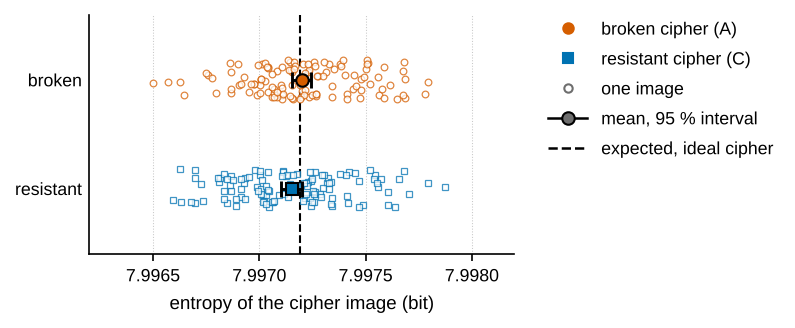

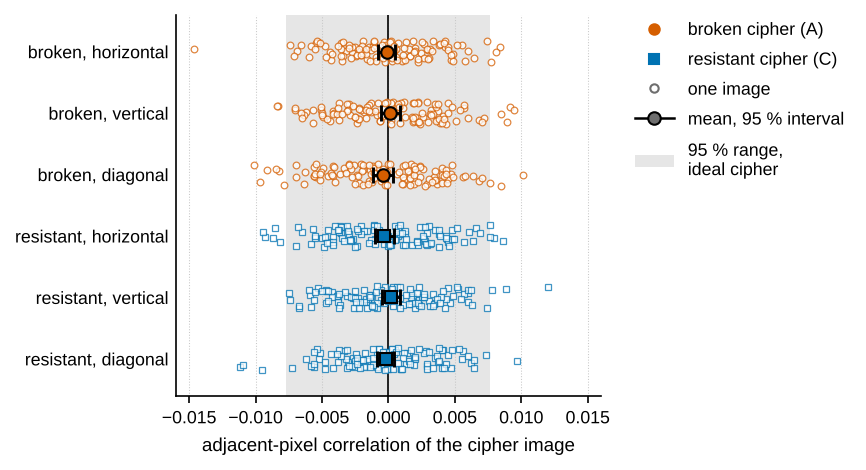

In [16]:
def metric_rows(metric, labels):
    rows = []
    for (cipher, text) in labels:
        part = per_image[per_image.cipher == cipher][metric]
        s = metric_summary[(metric_summary.cipher == cipher) & (metric_summary.metric == metric)].iloc[0]
        rows.append({"values": part.to_numpy(), "mean": s["mean"], "low": s["ci_low"], "high": s["ci_high"],
                     "label": text, "style": plotting.BROKEN if cipher == "broken" else plotting.RESISTANT})
    return rows


def battery_legend(fig, extra):
    base = [plotting.marker_handle(plotting.BROKEN, "broken cipher (A)"),
            plotting.marker_handle(plotting.RESISTANT, "resistant cipher (C)"),
            Line2D([], [], linestyle="none", marker="o", markerfacecolor="white", markeredgecolor=plotting.GREY,
                   markersize=4, label="one image"),
            Line2D([], [], color="black", marker="o", markerfacecolor=plotting.GREY, markersize=6,
                   label="mean, 95 % interval")]
    plotting.legend(fig, base + extra)


fig, ax = plotting.figure(5.6, legend_cm=5.2, left_cm=3.3)
plotting.dot_interval_plot(ax, metric_rows("entropy", [("broken", "broken"), ("resistant", "resistant")]),
                           rng("figure/jitter/entropy"))
expected = metrics.expected_entropy_uniform(N_FULL, Q)
ax.axvline(expected, color="black", linewidth=1.0, linestyle="--", zorder=1)
ax.set_xlim(7.9962, 7.9982)
ax.set_xticks([7.9965, 7.9970, 7.9975, 7.9980])
ax.xaxis.set_major_formatter(matplotlib.ticker.FormatStrFormatter("%.4f"))
ax.set_xlabel("entropy of the cipher image (bit)")
battery_legend(fig, [Line2D([], [], color="black", linestyle="--", label="expected, ideal cipher")])
publish(fig, "fig09_entropy")

pairs_hv = SIDE * (SIDE - 1)
band = 1.96 / np.sqrt(pairs_hv)
fig, ax = plotting.figure(8.0, legend_cm=5.2, left_cm=3.3)
labels = [(c, f"{c}, {d}") for c in ("broken", "resistant") for d in ("horizontal", "vertical", "diagonal")]
rows = []
for (c, text) in labels:
    direction = {"horizontal": "corr_h", "vertical": "corr_v", "diagonal": "corr_d"}[text.split(", ")[1]]
    rows += metric_rows(direction, [(c, text)])
ax.axvspan(-band, band, color=plotting.BAND, linewidth=0, zorder=0)
plotting.dot_interval_plot(ax, rows, rng("figure/jitter/correlation"))
ax.axvline(0, color="black", linewidth=0.8, zorder=1)
ax.set_xlim(-0.016, 0.016)
ax.set_xlabel("adjacent-pixel correlation of the cipher image")
battery_legend(fig, [Patch(facecolor=plotting.BAND, label="95 % range,\nideal cipher")])
publish(fig, "fig10_correlation")

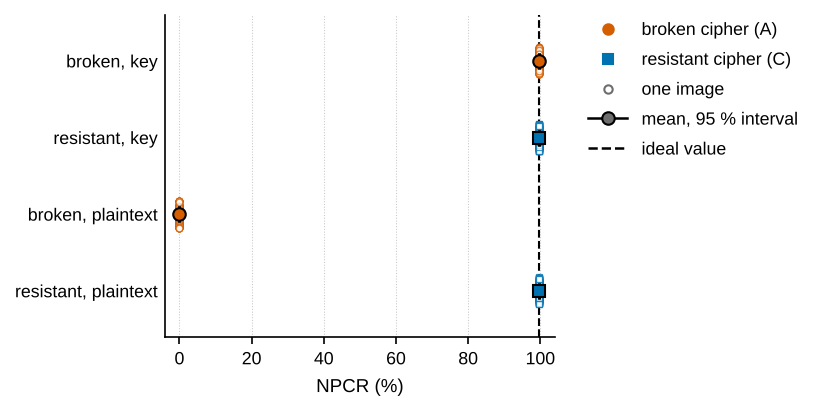

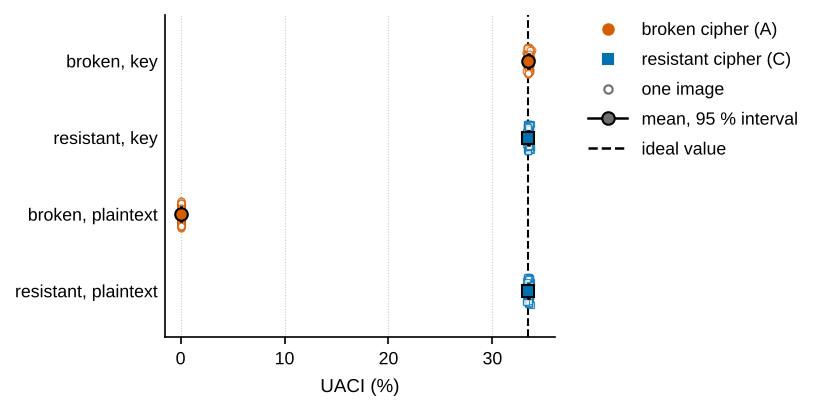

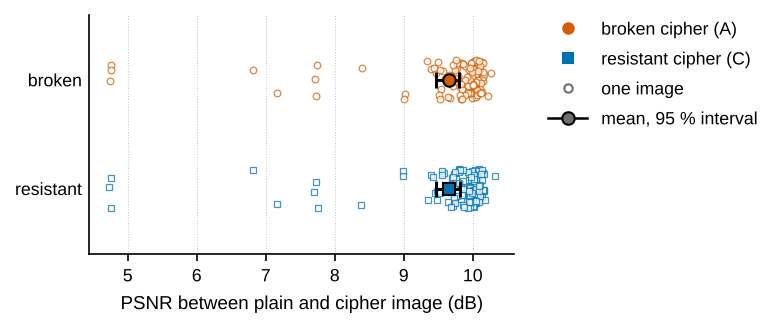

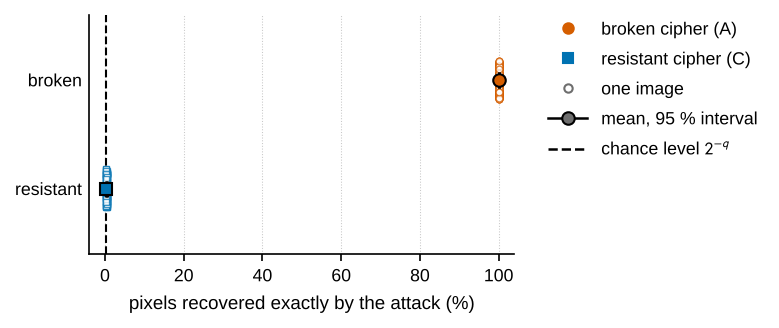

In [17]:
fig, ax = plotting.figure(7.0, legend_cm=5.2, left_cm=3.9)
rows = (metric_rows("key_npcr", [("broken", "broken, key"), ("resistant", "resistant, key")])
        + metric_rows("pt_npcr", [("broken", "broken, plaintext"), ("resistant", "resistant, plaintext")]))
plotting.dot_interval_plot(ax, rows, rng("figure/jitter/npcr"))
ax.axvline(metrics.npcr_ideal(Q), color="black", linewidth=1.0, linestyle="--", zorder=1)
ax.set_xlim(-4, 104)
ax.set_xlabel("NPCR (%)")
battery_legend(fig, [Line2D([], [], color="black", linestyle="--", label="ideal value")])
publish(fig, "fig11_npcr")

fig, ax = plotting.figure(7.0, legend_cm=5.2, left_cm=3.9)
rows = (metric_rows("key_uaci", [("broken", "broken, key"), ("resistant", "resistant, key")])
        + metric_rows("pt_uaci", [("broken", "broken, plaintext"), ("resistant", "resistant, plaintext")]))
plotting.dot_interval_plot(ax, rows, rng("figure/jitter/uaci"))
ax.axvline(metrics.uaci_ideal(Q), color="black", linewidth=1.0, linestyle="--", zorder=1)
ax.set_xlim(-1.5, 36)
ax.set_xlabel("UACI (%)")
battery_legend(fig, [Line2D([], [], color="black", linestyle="--", label="ideal value")])
publish(fig, "fig12_uaci")

fig, ax = plotting.figure(5.6, legend_cm=5.2, left_cm=3.3)
plotting.dot_interval_plot(ax, metric_rows("psnr", [("broken", "broken"), ("resistant", "resistant")]),
                           rng("figure/jitter/psnr"))
ax.set_xlabel("PSNR between plain and cipher image (dB)")
battery_legend(fig, [])
publish(fig, "fig13_psnr")

fig, ax = plotting.figure(5.6, legend_cm=5.2, left_cm=3.3)
rows = metric_rows("attack_recovery", [("broken", "broken"), ("resistant", "resistant")])
for row in rows:
    for k in ("values", "mean", "low", "high"):
        row[k] = 100 * np.asarray(row[k])
plotting.dot_interval_plot(ax, rows, rng("figure/jitter/recovery"))
ax.axvline(100 / L, color="black", linewidth=1.0, linestyle="--", zorder=1)
ax.set_xlim(-4, 104)
ax.set_xlabel("pixels recovered exactly by the attack (%)")
battery_legend(fig, [Line2D([], [], color="black", linestyle="--", label=r"chance level $2^{-q}$")])
publish(fig, "fig14_attack_recovery")

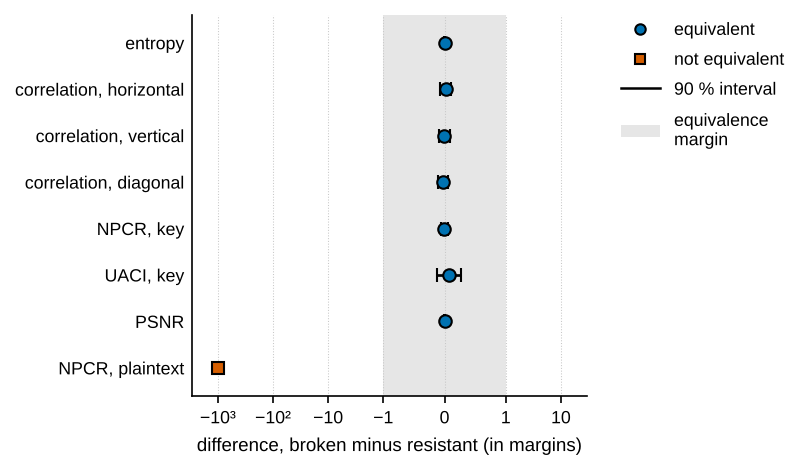

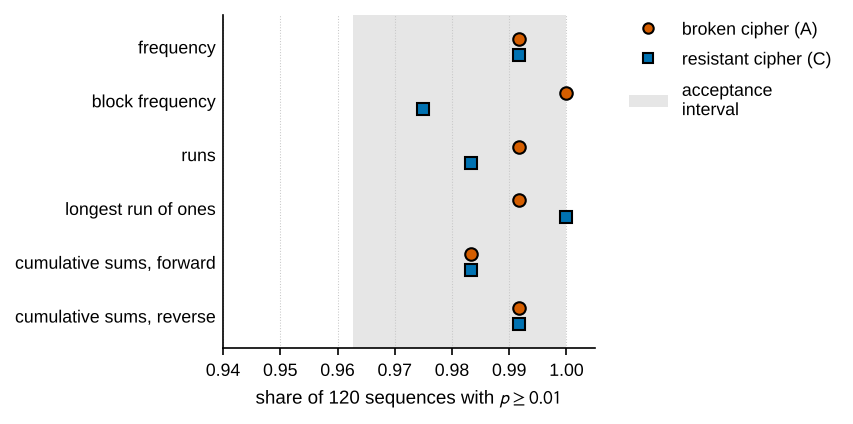

In [18]:
names_tost = {"entropy": "entropy", "corr_h": "correlation, horizontal", "corr_v": "correlation, vertical",
              "corr_d": "correlation, diagonal", "key_npcr": "NPCR, key", "key_uaci": "UACI, key",
              "psnr": "PSNR", "pt_npcr": "NPCR, plaintext"}
fig, ax = plotting.figure(8.0, legend_cm=5.0, left_cm=4.0)
ypos = np.arange(len(tost))[::-1]
ax.axvspan(-1, 1, color=plotting.BAND, linewidth=0, zorder=0)
for y, (_, r) in zip(ypos, tost.iterrows()):
    lo, mid, hi = r.ci_low / r.margin, r.difference / r.margin, r.ci_high / r.margin
    marker = "o" if r.equivalent else "s"
    colour = OI["blue"] if r.equivalent else OI["vermillion"]
    ax.errorbar(mid, y, xerr=[[mid - lo], [hi - mid]], fmt=marker, color="black", markerfacecolor=colour,
                markersize=6, elinewidth=1.3, capsize=3.5, zorder=3)
ax.set_xscale("symlog", linthresh=1.0, linscale=1.0)
ax.set_xlim(-3000, 30)
ax.set_xticks([-1000, -100, -10, -1, 0, 1, 10])
ax.set_xticklabels(["\u221210\u00b3", "\u221210\u00b2", "\u221210", "\u22121", "0", "1", "10"])
ax.set_yticks(ypos)
ax.set_yticklabels([names_tost[m] for m in tost.metric])
ax.tick_params(axis="y", length=0)
ax.set_ylim(-0.6, len(tost) - 0.4)
ax.set_xlabel("difference, broken minus resistant (in margins)")
ax.grid(axis="x", linestyle=":", linewidth=0.5, color="#C8C8C8", zorder=0)
plotting.legend(fig, [Line2D([], [], linestyle="none", marker="o", markerfacecolor=OI["blue"],
                             markeredgecolor="black", label="equivalent"),
                      Line2D([], [], linestyle="none", marker="s", markerfacecolor=OI["vermillion"],
                             markeredgecolor="black", label="not equivalent"),
                      Line2D([], [], color="black", label="90 % interval"),
                      Patch(facecolor=plotting.BAND, label="equivalence\nmargin")])
publish(fig, "fig15_tost")

test_names = {"frequency": "frequency", "block_frequency": "block frequency", "runs": "runs",
              "longest_run": "longest run of ones", "cusum_forward": "cumulative sums, forward",
              "cusum_reverse": "cumulative sums, reverse"}
fig, ax = plotting.figure(7.2, legend_cm=5.2, left_cm=4.2)
ypos = np.arange(len(metrics.NIST_TESTS))[::-1]
low = nist_summary.interval_low.iloc[0]
ax.axvspan(low, 1.0, color=plotting.BAND, linewidth=0, zorder=0)
for label, style, offset in (("broken", plotting.BROKEN, 0.15), ("resistant", plotting.RESISTANT, -0.15)):
    part = nist_summary[nist_summary.cipher == label].set_index("test").loc[list(metrics.NIST_TESTS)]
    ax.plot(part.proportion, ypos + offset, linestyle="none", marker=style["marker"], color=style["color"],
            markeredgecolor="black", markersize=6, zorder=3)
ax.set_yticks(ypos)
ax.set_yticklabels([test_names[t] for t in metrics.NIST_TESTS])
ax.tick_params(axis="y", length=0)
ax.set_ylim(-0.6, len(ypos) - 0.4)
ax.set_xlim(0.94, 1.005)
ax.set_xlabel(r"share of 120 sequences with $p \geq 0.01$")
ax.grid(axis="x", linestyle=":", linewidth=0.5, color="#C8C8C8", zorder=0)
plotting.legend(fig, [plotting.marker_handle(plotting.BROKEN, "broken cipher (A)", edgecolor="black"),
                      plotting.marker_handle(plotting.RESISTANT, "resistant cipher (C)", edgecolor="black"),
                      Patch(facecolor=plotting.BAND, label="acceptance\ninterval")])
publish(fig, "fig16_nist")

## 10. Final results

The table and the text below are generated from `results` and summarise every number that the
paper reports. `results/results.json` holds the complete record.

In [19]:
e1, e2, e4 = results["e1"], results["e2"], results["e4"]
cov = results["e3_coverage"]
s = e4["summary"]
t = e4["tost"]
final = pd.DataFrame([
    ("E1", "exhaustive cases, pixel path vs state path", f"{e1['small_cases']} cases, {e1['small_state_mismatches']} mismatches"),
    ("E1", "dense non-basis-preserving realisations", f"{e1['small_dense_mismatches']} mismatches, max error {e1['dense_vs_permutation_max_error']:.1e}"),
    ("E1", "full-size images, state dimension 2^24", f"{e1['full_images']} images, {e1['full_mismatches']} mismatches"),
    ("E1", "scheme F on bit planes, state dimension 2^20", f"{e1['full_f_bit_level_mismatches']} mismatches"),
    ("E2", "excluded gate, undefined images", "; ".join(f"n={r['n']}, q={r['q']}: {r['undefined']}/{r['total']}" for r in e2["excluded_gate"])),
    ("E2", "scheme F, one-pixel change spreads", f"to {e2['spread_f_mean']:.2f} pixels on average, at most {e2['spread_f_max']}"),
    ("E3", "generic attack, schemes A B D E", ", ".join(f"{x}: {cov[x + '/generic']['exact_keys']}/5 exact" for x in "ABDE")),
    ("E3", "queries at N = 65536: generic, XOR, bit level", f"{cov['A/generic']['queries']}, {cov['A/xor']['queries']}, {cov['F/bit-level']['queries']}"),
    ("E3", "lower bounds at N = 65536", f"{attack.generic_lower_bound(N_FULL, Q)}, {attack.xor_lower_bound(N_FULL, Q)}, {attack.bit_level_lower_bound(N_FULL, Q)}"),
    ("E3", "scheme C (plaintext-dependent), best recovery", f"{100 * results['e3_boundaries']['plaintext_dependent_recovered_max']:.2f} %"),
    ("E3", "Hadamard before readout, two readouts differ", f"{100 * results['e3_boundaries']['hadamard_two_readouts_differ']:.1f} % of pixels"),
    ("E4", "entropy, broken / resistant", f"{s['broken/entropy']['mean']:.5f} / {s['resistant/entropy']['mean']:.5f} bit"),
    ("E4", "key NPCR, broken / resistant", f"{s['broken/key_npcr']['mean']:.3f} / {s['resistant/key_npcr']['mean']:.3f} %"),
    ("E4", "plaintext NPCR, broken / resistant", f"{s['broken/pt_npcr']['mean']:.4f} / {s['resistant/pt_npcr']['mean']:.3f} %"),
    ("E4", "attack recovery, broken / resistant", f"{100 * s['broken/attack_recovery']['mean']:.2f} / {100 * s['resistant/attack_recovery']['mean']:.2f} %"),
    ("E4", "TOST equivalence on the battery", ", ".join(f"{m}: p={t[m]['p_tost']:.1e}" for m in MARGINS)),
    ("E4", "TOST, plaintext NPCR", f"p = {t['pt_npcr']['p_tost']:.2f}, equivalent = {t['pt_npcr']['equivalent']}"),
    ("E4", "NIST second level passed (broken, resistant)", f"{e4['nist_all_pass']['broken']}, {e4['nist_all_pass']['resistant']}"),
], columns=["experiment", "quantity", "result"])
display(final)

with open(RESULTS / "results.json", "w") as fh:
    json.dump(results, fh, indent=1, sort_keys=True, default=lambda o: o.item() if hasattr(o, "item") else str(o))
with open(RESULTS / "run_info.json", "w") as fh:
    json.dump(run_info, fh, indent=1, sort_keys=True)
deterministic = sorted(p for p in RESULTS.iterdir() if p.suffix in (".json", ".csv") and p.name != "run_info.json")
with open(RESULTS / "SHA256SUMS", "w") as fh:
    for p in deterministic:
        fh.write(f"{hashlib.sha256(p.read_bytes()).hexdigest()}  {p.name}\n")
print((RESULTS / "SHA256SUMS").read_text())
print("figures:", ", ".join(sorted(p.name for p in FIGURES.glob("*.png"))))

,experiment,quantity,result
0,E1,"exhaustive cases, pixel path vs state path","541696 cases, 0 mismatches"
1,E1,dense non-basis-preserving realisations,"0 mismatches, max error 2.8e-16"
2,E1,"full-size images, state dimension 2^24","120 images, 0 mismatches"
3,E1,"scheme F on bit planes, state dimension 2^20",0 mismatches
4,E2,"excluded gate, undefined images","n=2, q=2: 192/256; n=2, q=3: 3072/4096; n=3, q..."
5,E2,"scheme F, one-pixel change spreads","to 3.94 pixels on average, at most 8"
6,E3,"generic attack, schemes A B D E","A: 5/5 exact, B: 5/5 exact, D: 5/5 exact, E: 5..."
7,E3,"queries at N = 65536: generic, XOR, bit level","257, 3, 20"
8,E3,lower bounds at N = 65536,"213, 3, 19"
9,E3,"scheme C (plaintext-dependent), best recovery",0.41 %


e28f602f0414d9be4a860f4498242d738d6da43a0fcfa669ac95893c62d7810e  attack_coverage.csv
cd6360adcfece035cb8c0c116e909ab03bec96073ef5cfa1741670bf81f5e2a0  ensemble_statistics.csv
91ab88abbd2cb3f1c4080a6731adff29d3c9c0c6b316c67395bfe7080e46f822  nist_pvalues.csv
8326702fa7d0b0865cb68cacbbbde4057ea504236d74d0d06157c8c6bb13243a  per_image_metrics.csv
ea8aa72e40868ba12d6e177c149ebc828856c566084194c440e21167407e40cb  query_scaling.csv
33ab341ddc3a7fe89abc4d8059294a24b541518a9e6f2642197905d2fdcb6cbb  results.json

figures: fig01_representation_independence.png, fig02_ensemble_spectra.png, fig03_excluded_gate.png, fig04_single_pixel_spread.png, fig05_attack_example.png, fig06_recovery_vs_queries.png, fig07_attack_coverage.png, fig08_query_cost.png, fig09_entropy.png, fig10_correlation.png, fig11_npcr.png, fig12_uaci.png, fig13_psnr.png, fig14_attack_recovery.png, fig15_tost.png, fig16_nist.png


In [20]:
display(Markdown(f'''
**Conclusions.**

* The pixel path and the state path agree on all {e1['small_cases']} exhaustively enumerated images and on all
  {e1['full_images']} full-size images, and dense realisations that are not basis preserving produce the same
  cipher images. The quantum representation does not change the cipher (Corollary 2).
* A gate whose position map depends on the value leaves the cipher image undefined for
  {e2['excluded_gate'][0]['undefined']} of {e2['excluded_gate'][0]['total']} images at $n=q=2$, and per-plane
  permutations spread a one-pixel change to {e2['spread_f_mean']:.2f} cipher pixels on average, so neither is an NEQR cipher.
* One attack recovers the equivalent key of every plaintext-independent scheme exactly, with
  {cov['A/generic']['queries']} queries for any bijective value layer, {cov['A/xor']['queries']} for XOR diffusion and
  {cov['F/bit-level']['queries']} at bit level, against lower bounds of {attack.generic_lower_bound(N_FULL, Q)},
  {attack.xor_lower_bound(N_FULL, Q)} and {attack.bit_level_lower_bound(N_FULL, Q)}.
* The broken cipher and the resistant cipher are statistically equivalent on entropy, all three correlations,
  key-sensitivity NPCR and UACI and PSNR (paired TOST, largest p = {max(t[m]['p_tost'] for m in MARGINS):.1e}), and both pass
  the NIST second-level checks. Only plaintext sensitivity separates them
  ({s['broken/pt_npcr']['mean']:.4f} % against {s['resistant/pt_npcr']['mean']:.3f} %), and that is a property of the key
  schedule, not of the representation.
'''))


**Conclusions.**

* The pixel path and the state path agree on all 541696 exhaustively enumerated images and on all
  120 full-size images, and dense realisations that are not basis preserving produce the same
  cipher images. The quantum representation does not change the cipher (Corollary 2).
* A gate whose position map depends on the value leaves the cipher image undefined for
  192 of 256 images at $n=q=2$, and per-plane
  permutations spread a one-pixel change to 3.94 cipher pixels on average, so neither is an NEQR cipher.
* One attack recovers the equivalent key of every plaintext-independent scheme exactly, with
  257 queries for any bijective value layer, 3 for XOR diffusion and
  20 at bit level, against lower bounds of 213,
  3 and 19.
* The broken cipher and the resistant cipher are statistically equivalent on entropy, all three correlations,
  key-sensitivity NPCR and UACI and PSNR (paired TOST, largest p = 7.2e-13), and both pass
  the NIST second-level checks. Only plaintext sensitivity separates them
  (0.0015 % against 99.608 %), and that is a property of the key
  schedule, not of the representation.
